# 06 · Modelado: baseline y comparación de modelos

Usa el código de `src/` para que el notebook y el entrenamiento den los mismos resultados.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

from src.pipeline import cargar_datos, partir, candidatos
from src.train import comparar, metricas_test

X, y = cargar_datos()
X_train, X_test, y_train, y_test = partir(X, y)
print("entrenamiento:", X_train.shape, "| prueba:", X_test.shape)
print("proporción de falsos en train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

entrenamiento: (1078, 4) | prueba: (270, 4)
proporción de falsos en train/test: 0.453 0.452


## Comparación con validación cruzada (solo datos de entrenamiento)

In [2]:
tabla = comparar(X_train, y_train)
tabla.round(4)

,modelo,accuracy,recall,precision,f1
0,svm_rbf,0.9991,1.0000,0.9980,0.9990
1,svm_rbf_sin_entropy,0.9963,1.0000,0.9919,0.9959
2,knn,0.9944,1.0000,0.9879,0.9939
3,regresion_logistica,0.9944,0.9980,0.9899,0.9939
4,random_forest,0.9916,0.9980,0.9840,0.9909
5,gradient_boosting,0.9889,0.9939,0.9820,0.9878
6,baseline_solo_variance,0.8479,0.8259,0.8365,0.8307
7,baseline_mayoritaria,0.5473,0.0000,0.0000,0.0000


## Modelo elegido: SVM RBF. Evaluación en test (una sola vez)

{'accuracy': 1.0, 'recall_falso': 1.0, 'precision_falso': 1.0, 'f1_falso': 1.0, 'tasa_rechazo_billetes_buenos': 0.0, 'matriz': {'tn': 148, 'fp': 0, 'fn': 0, 'tp': 122}, 'n_test': 270}


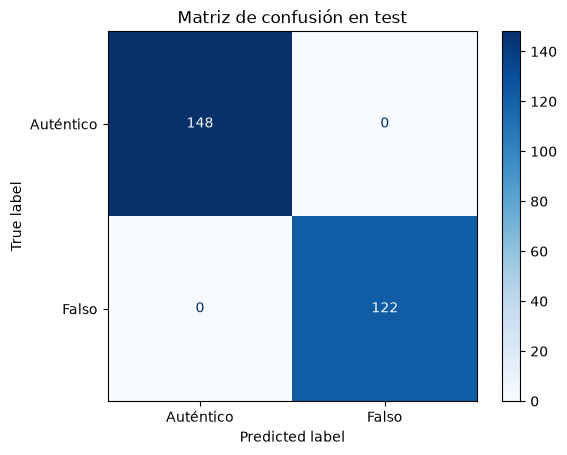

In [3]:
modelo = candidatos()["svm_rbf"].fit(X_train, y_train)
res = metricas_test(modelo, X_test, y_test)
print(res)
ConfusionMatrixDisplay.from_estimator(modelo, X_test, y_test, display_labels=["Auténtico", "Falso"], cmap="Blues")
plt.title("Matriz de confusión en test")
plt.show()

## Sensibilidad al umbral

Si aceptar un billete falso cuesta más que rechazar uno bueno, se puede bajar el umbral de probabilidad para rechazar.

In [4]:
import numpy as np
from sklearn.metrics import recall_score

proba = modelo.predict_proba(X_test)[:, 1]
for umbral in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred = (proba >= umbral).astype(int)
    rechazo_buenos = ((pred == 1) & (y_test == 0)).sum() / (y_test == 0).sum()
    print(f"umbral {umbral}: recall falso = {recall_score(y_test, pred):.3f} | rechazo de buenos = {rechazo_buenos:.3f}")

umbral 0.1: recall falso = 1.000 | rechazo de buenos = 0.007
umbral 0.3: recall falso = 1.000 | rechazo de buenos = 0.007
umbral 0.5: recall falso = 1.000 | rechazo de buenos = 0.000
umbral 0.7: recall falso = 1.000 | rechazo de buenos = 0.000
umbral 0.9: recall falso = 1.000 | rechazo de buenos = 0.000
